In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd
df=pd.read_csv("emergency_service.csv")
df

,Timestamp,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,Road_Type,Emergency_Level,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Response_Time
0,01/01/2018 00:00,Low,Cardiac Arrest,Suburban,High,Clear,Available,91,8.89,1,Unavailable,Highway,Major,43.549849,90.030756,Severe,AI,20.870220
1,01/01/2018 00:10,Low,Other,Urban,Moderate,Clear,Available,28,28.10,2,Unavailable,Highway,Critical,30.687975,88.255008,Moderate,Human,24.486195
2,01/01/2018 00:20,Medium,Cardiac Arrest,Suburban,High,Rainy,Available,83,40.43,1,Unavailable,Unpaved Road,Minor,44.456331,97.719622,No Impact,Human,18.760740
3,01/01/2018 00:30,Low,Accident,Urban,Moderate,Clear,Available,31,18.97,3,Available,Highway,Minor,35.879968,60.234672,No Impact,Human,18.169534
4,01/01/2018 00:40,Low,Cardiac Arrest,Urban,Moderate,Stormy,Available,52,16.31,3,Available,Highway,Minor,26.369383,71.083564,Moderate,Human,5.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368060,30/12/2024 23:20,Medium,Cardiac Arrest,Rural,Low,Clear,Available,85,24.11,3,Unavailable,Highway,Minor,52.560965,52.118376,Moderate,Human,12.465708
368061,30/12/2024 23:30,High,Accident,Suburban,Low,Clear,Available,45,43.26,1,Unavailable,Highway,Minor,42.738073,71.485832,Moderate,Human,11.006577
368062,30/12/2024 23:40,Low,Fire,Urban,Moderate,Rainy,Unavailable,97,42.13,1,Available,Unpaved Road,Minor,43.578888,51.960692,Moderate,Human,16.782428
368063,30/12/2024 23:50,Medium,Accident,Urban,Moderate,Clear,Available,37,39.57,2,Unavailable,Highway,Major,30.379377,87.275648,No Impact,Human,14.063774


In [3]:
df['Timestamp']=pd.to_datetime(df['Timestamp'],format='%d/%m/%Y %H:%M')

In [4]:
df_subset=df[(df['Timestamp'] >= '2022-01-01') & (df['Timestamp'] <='2024-12-31')]

In [5]:
# Activity 1: Descriptive Analytics

#In this activity, descriptive analytics is used to understand historical emergency response data.
#The analysis focuses on response time and how it is affected by traffic congestion, weather,
#incident severity, region type, and resource availability.

In [6]:
df_subset.head()

,Timestamp,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,Road_Type,Emergency_Level,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Response_Time
210384,2022-01-01 00:00:00,Medium,Accident,Urban,Low,Clear,Available,75,9.80,1,Unavailable,Highway,Minor,49.424852,82.031051,Moderate,AI,13.510247
210385,2022-01-01 00:10:00,Low,Fire,Urban,Low,Clear,Available,85,39.16,1,Available,Highway,Minor,34.188224,93.735875,No Impact,Human,16.654818
210386,2022-01-01 00:20:00,Low,Cardiac Arrest,Urban,High,Clear,Available,26,10.43,1,Unavailable,Local Road,Minor,46.330663,100.000000,No Impact,Human,17.802266
210387,2022-01-01 00:30:00,Low,Accident,Urban,Moderate,Rainy,Available,60,39.85,1,Unavailable,Highway,Minor,41.498126,88.131774,No Impact,Human,5.000000
210388,2022-01-01 00:40:00,Low,Accident,Rural,Low,Clear,Available,93,38.59,1,Unavailable,Highway,Minor,32.398124,73.247545,Moderate,Human,15.354402


In [6]:
df_subset.dtypes

Timestamp                  datetime64[ns]
Incident_Severity                  object
Incident_Type                      object
Region_Type                        object
Traffic_Congestion                 object
Weather_Condition                  object
Ambulance_Availability             object
Hospital_Capacity                   int64
Distance_to_Incident              float64
Number_of_Injuries                  int64
Specialist_Availability            object
Road_Type                          object
Emergency_Level                    object
Ambulance_Speed                   float64
Fuel_Level                        float64
Weather_Impact                     object
Dispatch_Coordinator               object
Response_Time                     float64
dtype: object

In [7]:
df_subset.columns

Index(['Timestamp', 'Incident_Severity', 'Incident_Type', 'Region_Type',
       'Traffic_Congestion', 'Weather_Condition', 'Ambulance_Availability',
       'Hospital_Capacity', 'Distance_to_Incident', 'Number_of_Injuries',
       'Specialist_Availability', 'Road_Type', 'Emergency_Level',
       'Ambulance_Speed', 'Fuel_Level', 'Weather_Impact',
       'Dispatch_Coordinator', 'Response_Time'],
      dtype='object')

In [8]:
df_subset.shape

(157681, 18)

In [9]:
df_subset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 157681 entries, 210384 to 368064
Data columns (total 18 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   Timestamp                157681 non-null  datetime64[ns]
 1   Incident_Severity        157681 non-null  object        
 2   Incident_Type            157681 non-null  object        
 3   Region_Type              157681 non-null  object        
 4   Traffic_Congestion       157681 non-null  object        
 5   Weather_Condition        157681 non-null  object        
 6   Ambulance_Availability   157681 non-null  object        
 7   Hospital_Capacity        157681 non-null  int64         
 8   Distance_to_Incident     157681 non-null  float64       
 9   Number_of_Injuries       157681 non-null  int64         
 10  Specialist_Availability  157681 non-null  object        
 11  Road_Type                157681 non-null  object        
 12  Emergency_Level 

In [10]:
df_subset.describe()

,Timestamp,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Ambulance_Speed,Fuel_Level,Response_Time
count,157681,157681.000000,157681.000000,157681.000000,157681.000000,157681.000000,157681.000000
mean,2023-07-02 11:59:59.999999232,54.523735,25.506964,1.520475,40.029138,69.857698,15.058278
min,2022-01-01 00:00:00,10.000000,1.000000,1.000000,20.000000,10.138465,5.000000
25%,2022-10-01 18:00:00,32.000000,13.240000,1.000000,34.596855,59.840729,11.651596
50%,2023-07-02 12:00:00,54.000000,25.510000,1.000000,40.014632,69.972216,15.010456
75%,2024-04-01 06:00:00,77.000000,37.790000,2.000000,45.432415,80.045142,18.394115
max,2024-12-31 00:00:00,99.000000,50.000000,4.000000,77.801028,100.000000,30.000000
std,NaN,25.934344,14.157189,0.729011,7.959104,14.677312,4.891345


In [19]:
#measures of tendancy
numeric_col=[ 'Response_Time', 'Distance_to_Incident', 'Hospital_Capacity',
 'Ambulance_Speed','Fuel_Level','Number_of_Injuries']

# now we`re gonna calculate the mean 
mean_values = df_subset[numeric_col].mean()

#now the median 
median_values=df_subset[numeric_col].median()

# here , i made a table to make it more organized
central_tendency = pd.DataFrame({
    'Mean': mean_values,
    'Median': median_values
})

central_tendency
# here, we showed the mean and median to know better about the numerical data 

,Mean,Median
Response_Time,15.058278,15.010456
Distance_to_Incident,25.506964,25.510000
Hospital_Capacity,54.523735,54.000000
Ambulance_Speed,40.029138,40.014632
Fuel_Level,69.857698,69.972216
Number_of_Injuries,1.520475,1.000000


In [21]:
#measures of tendancy
#for the catarogical data , im gonna use :
# Mode for categorical columns
# Select all categorical columns using select dtypes 
categorical_columns = df_subset.select_dtypes(include='object').columns

# mode : most frequnt value , iloc[0]: take the first vlaue from the row
mode_values = df_subset[categorical_columns].mode().iloc[0]
mode_values


Incident_Severity                  Low
Incident_Type                 Accident
Region_Type                      Urban
Traffic_Congestion                 Low
Weather_Condition                Clear
Ambulance_Availability       Available
Specialist_Availability    Unavailable
Road_Type                      Highway
Emergency_Level                  Minor
Weather_Impact               No Impact
Dispatch_Coordinator             Human
Name: 0, dtype: object

In [22]:
#now , measures of despersion 
#These values show how much the response time varies in the dataset
#first : range =max valu-min value 
#The range shows the difference between the highest and lowest response time.
# im gonna calculate teh response time because it is the target 
response_range = df_subset['Response_Time'].max() - df_subset['Response_Time'].min()
print("Range:", response_range)

Range: 25.0


In [24]:
response_variance = df_subset['Response_Time'].var()
print("Variance:", response_variance)

Variance: 23.925257357718635


In [25]:
#The standard deviation shows whether response times are close to the average or spread out.
response_std = df_subset['Response_Time'].std()
print("Standard Deviation:", response_std)

Standard Deviation: 4.89134514808745


In [7]:
#The IQR shows the spread of the middle part of the response time values.
q1 = df_subset['Response_Time'].quantile(0.25)
q3 = df_subset['Response_Time'].quantile(0.75)
response_iqr = q3 - q1
print("IQR:", response_iqr)

IQR: 6.742519669999998


In [8]:
# 0ther measures of position for Response Time
q2 = df_subset['Response_Time'].quantile(0.50)
p10 = df_subset['Response_Time'].quantile(0.10)
p90 = df_subset['Response_Time'].quantile(0.90)

print("Q2(median) :", q2)
print("10th Percentile:", p10)
print("90th Percentile:", p90)
#measures of position help us understand where response time values are located in the dataset.
#The median shows the middle response time value.
#The 10th percentile means that 10% of response times are below this value.
#The 90th percentile means that 90% of response times are below this value.

Q2(median) : 15.01045556
10th Percentile: 8.613886196
90th Percentile: 21.43273528


In [11]:
lower_part = q1 - (1.5 * response_iqr)
#lower that the lower fence considered outlier, same to the upper 
upper_part = q3 + (1.5 * response_iqr)
outliers = df_subset[
    (df_subset['Response_Time'] < lower_part) |
    (df_subset['Response_Time'] > upper_part)]
print("Lower Fence:", lower_part)
print("Upper Fence:", upper_part)
print("Number of outliers:", len(outliers))

Lower Fence: 1.5378162850000034
Upper Fence: 28.507894964999995
Number of outliers: 554


In [27]:
#The coefficient of variation shows the spread of response time compared to its average.
#It is useful because it expresses variation as a percentage.
#A higher CV means the response time is less stable, while a lower CV means the response time is more consistent.
response_cv = (response_std / df_subset['Response_Time'].mean()) * 100
print("Coefficient of variation:", response_cv)

Coefficient of Variation: 32.48276616928758


In [28]:
# i like to organize them in a table to make it easier to read and analyze 
#so:
response_dispersion = pd.DataFrame({'Measure': [ 'Range', 'Variance',
        'Standard Deviation','IQR', 'Coefficient of Variation'],
                                    
    'Value': [response_range,response_variance, response_std,response_iqr,response_cv]
})

response_dispersion

,Measure,Value
0,Range,25.000000
1,Variance,23.925257
2,Standard Deviation,4.891345
3,IQR,6.742520
4,Coefficient of Variation,32.482766


In [30]:
#after despersion , i want to analyze thr frquncy tables for the catarogical vales
#for easier apllication , i will define a function to pass through all tha cat data
#The frequency tables show the most common categories in the dataset.
#this helps the emergency response center understand the most frequent incident types, traffic conditions, weather impacts, and region types.

# Function to create frequency table for any categorical column

def frequency_table(column_name):
    frequency = df_subset[column_name].value_counts()
    percentage = df_subset[column_name].value_counts(normalize=True) * 100
    table = pd.DataFrame({
        'Frequency': frequency,
        'Percentage (%)': percentage
    })
    return table

In [41]:
print(categorical_columns)
print(len(categorical_columns))

Index(['Incident_Severity', 'Incident_Type', 'Region_Type',
       'Traffic_Congestion', 'Weather_Condition', 'Ambulance_Availability',
       'Specialist_Availability', 'Road_Type', 'Emergency_Level',
       'Weather_Impact', 'Dispatch_Coordinator'],
      dtype='object')
11


In [32]:
frequency_table('Incident_Type')

,Frequency,Percentage (%)
Incident_Type,,
Accident,78772,49.956558
Cardiac Arrest,31756,20.139395
Other,31498,19.975774
Fire,15655,9.928273


In [33]:
frequency_table('Traffic_Congestion')

,Frequency,Percentage (%)
Traffic_Congestion,,
Low,78991,50.095446
Moderate,62956,39.926180
High,15734,9.978374


In [34]:

frequency_table('Weather_Condition')

,Frequency,Percentage (%)
Weather_Condition,,
Clear,126152,80.004566
Rainy,23675,15.014491
Stormy,7854,4.980943


In [35]:
frequency_table('Incident_Severity')

,Frequency,Percentage (%)
Incident_Severity,,
Low,94582,59.983130
Medium,47422,30.074644
High,15677,9.942225


In [36]:
frequency_table('Ambulance_Availability')

,Frequency,Percentage (%)
Ambulance_Availability,,
Available,141838,89.952499
Unavailable,15843,10.047501


In [37]:
frequency_table('Region_Type')

,Frequency,Percentage (%)
Region_Type,,
Urban,110195,69.884767
Suburban,31743,20.131151
Rural,15743,9.984082


In [11]:
df_subset.isnull().sum()

Timestamp                  0
Incident_Severity          0
Incident_Type              0
Region_Type                0
Traffic_Congestion         0
Weather_Condition          0
Ambulance_Availability     0
Hospital_Capacity          0
Distance_to_Incident       0
Number_of_Injuries         0
Specialist_Availability    0
Road_Type                  0
Emergency_Level            0
Ambulance_Speed            0
Fuel_Level                 0
Weather_Impact             0
Dispatch_Coordinator       0
Response_Time              0
dtype: int64

In [12]:
df_subset.duplicated().sum()

np.int64(0)

In [27]:
df_subset.shape

(157681, 18)

In [28]:
df_subset["Response_Time"].describe()
#the target values is response time

count    157681.000000
mean         15.058278
std           4.891345
min           5.000000
25%          11.651596
50%          15.010456
75%          18.394115
max          30.000000
Name: Response_Time, dtype: float64

In [29]:
df_subset["Road_Type"].value_counts()

Road_Type
Highway         94545
Local Road      47403
Unpaved Road    15733
Name: count, dtype: int64

In [43]:
#next step : groupby analysis 
# Average response time for each traffic congestion level
traffic_response = df_subset.groupby('Traffic_Congestion')['Response_Time'].mean()
traffic_response
#This table shows the average response time for each traffic congestion level.
#It helps us understand if traffic congestion affects emergency response performance.

Traffic_Congestion
High        15.046504
Low         15.075196
Moderate    15.039993
Name: Response_Time, dtype: float64

In [13]:
#here, i took just a few catarogical columns 
#to see the relations , i chosse them based on the assignment 
# average response time for each weather impact level
weather_response = df_subset.groupby('Weather_Impact')['Response_Time'].mean()
weather_response

Weather_Impact
Moderate     15.055783
No Impact    15.061264
Severe       15.028778
Name: Response_Time, dtype: float64

In [15]:
# average response time for each incident severity level
severity_response = df_subset.groupby('Incident_Severity')['Response_Time'].mean()
severity_response

Incident_Severity
High      15.023196
Low       15.054656
Medium    15.077099
Name: Response_Time, dtype: float64

In [20]:
# average response time by ambulance availability
ambulance_response = df_subset.groupby('Ambulance_Availability')['Response_Time'].mean()
ambulance_response

Ambulance_Availability
Available      15.066098
Unavailable    14.988265
Name: Response_Time, dtype: float64

In [47]:
# average response time for each region type
region_response = df_subset.groupby('Region_Type')['Response_Time'].mean()
region_response

Region_Type
Rural       15.124743
Suburban    15.008821
Urban       15.063029
Name: Response_Time, dtype: float64

In [18]:
# Average response time for each region type
Emergency_response = df_subset.groupby('Emergency_Level')['Response_Time'].mean()
Emergency_response

Emergency_Level
Critical    15.038178
Major       15.041631
Minor       15.065946
Name: Response_Time, dtype: float64

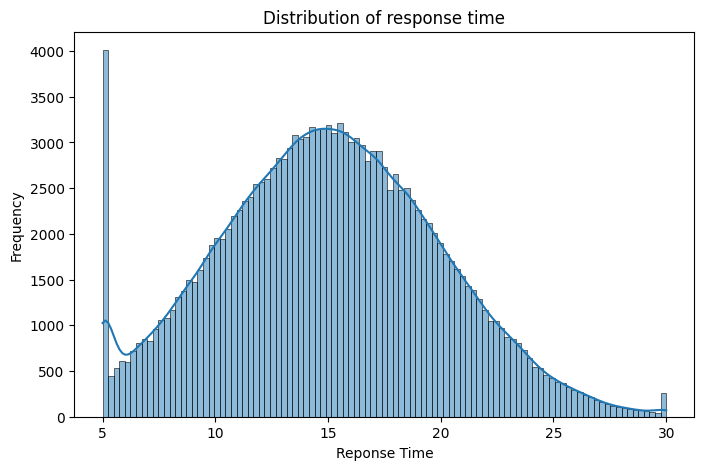

In [40]:
plt.figure(figsize=(8,5))
sns.histplot(df_subset['Response_Time'],kde=True)

plt.xlabel("Reponse Time (min)")
plt.ylabel("Frequency")
plt.title("Distribution of response time")
plt.show()

#insights:
# The distribution shows that most emergency response times are around 15 minutes. 
# The response time ranges approximately from 5 to 30 minutes,
# with fewer incidents occurring at extremely low or high response times.

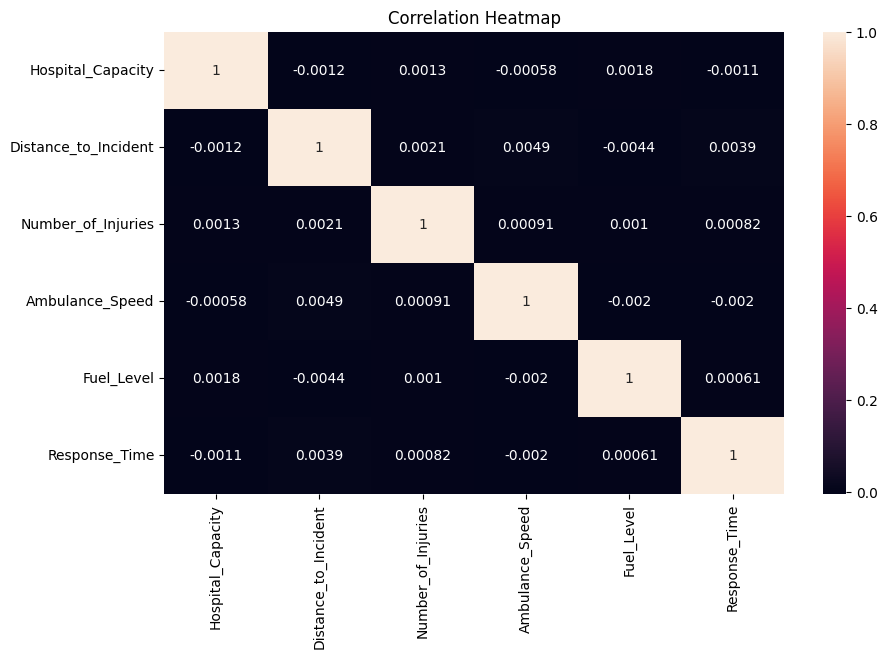

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
numeric_df=df_subset.select_dtypes(include='number')

plt.figure(figsize=(10,6))
sns.heatmap(numeric_df.corr(),
           annot=True,
           )
plt.title('Correlation Heatmap')
plt.show()
#the relations between the data are weak. 

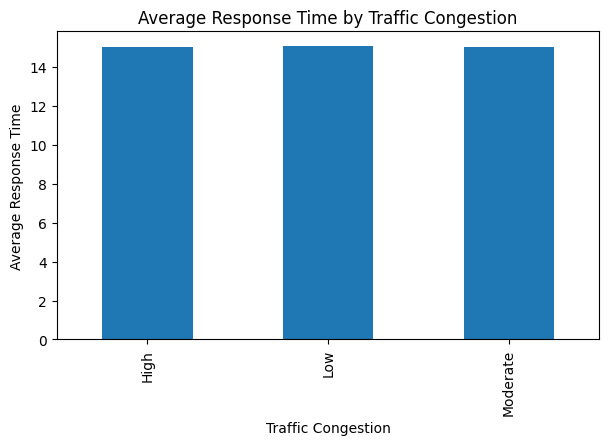

In [49]:
# visualization , now we want to visualize the tables i made
# 1-bar chart for average response time by traffic congestion 
# those for group by  because it has a relations with the target 
traffic_response.plot(kind='bar', figsize=(7,4))
plt.title('Average Response Time by Traffic Congestion')
plt.xlabel('Traffic Congestion')
plt.ylabel('Average Response Time')
plt.show()
# we can see that the data is strange 
# No clear difference is observed between traffic congestion levels and response time,
# suggesting a weak relationship in the dataset.
#This chart shows the average response time for each traffic congestion level.
#It helps us understand if traffic congestion affects emergency response performance.

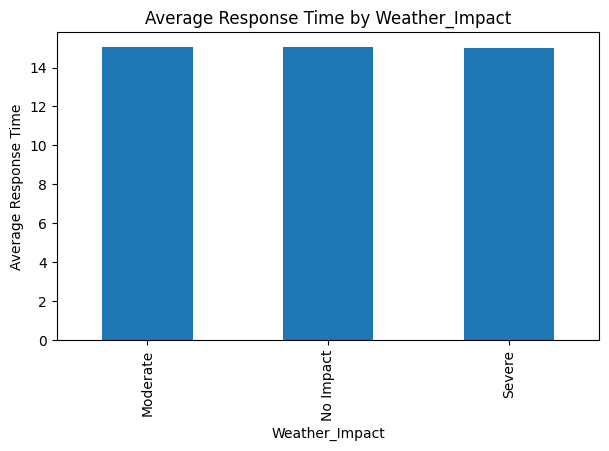

In [14]:
weather_response.plot(kind='bar', figsize=(7,4))
plt.title('Average Response Time by Weather_Impact')
plt.xlabel('Weather_Impact')
plt.ylabel('Average Response Time')
plt.show()

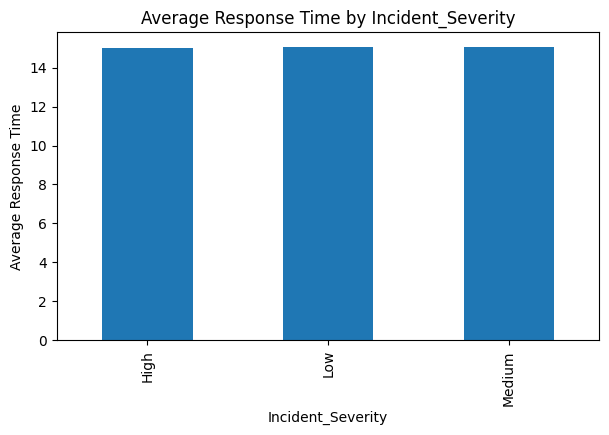

In [19]:
severity_response.plot(kind='bar', figsize=(7,4))
plt.title('Average Response Time by Incident_Severity')
plt.xlabel('Incident_Severity')
plt.ylabel('Average Response Time')
plt.show()

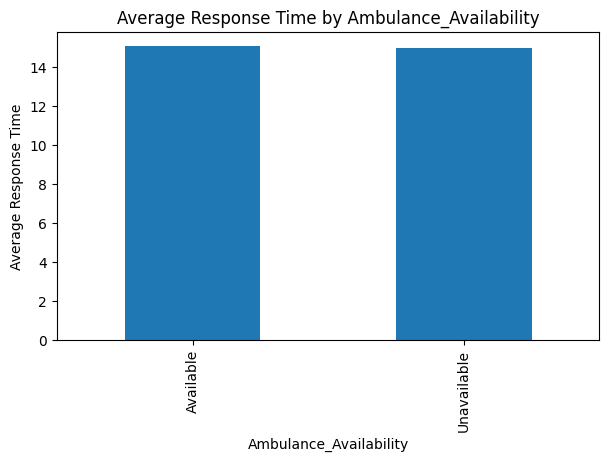

In [21]:
ambulance_response.plot(kind='bar', figsize=(7,4))
plt.title('Average Response Time by Ambulance_Availability')
plt.xlabel('Ambulance_Availability')
plt.ylabel('Average Response Time')
plt.show()
#The average response time is very close across traffic congestion, weather impact, and incident severity categories.
#This means these categorical variables do not show a strong visible effect on response time in this dataset.

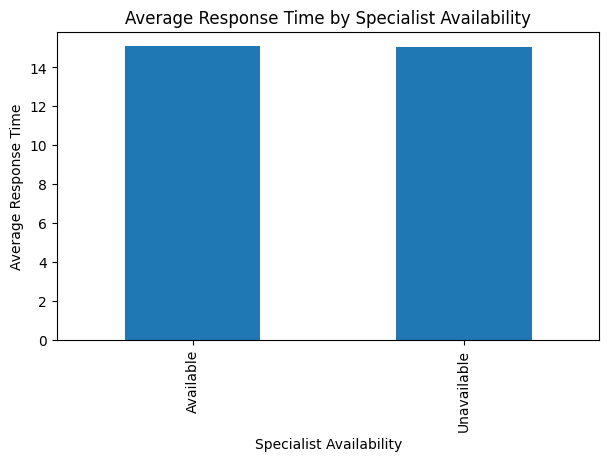

In [77]:
# Bar chart for average response time by specialist availability
specialist_response = df_subset.groupby('Specialist_Availability')['Response_Time'].mean()

specialist_response.plot(kind='bar', figsize=(7,4))
plt.title('Average Response Time by Specialist Availability')
plt.xlabel('Specialist Availability')
plt.ylabel('Average Response Time')
plt.show()
#so unclear 
#Specialist availability is an important resource factor in emergency response.
#If the average response time is higher when specialists are not available, 
#this may mean that limited specialist resources can cause delays.
# but here the data is so unclear 

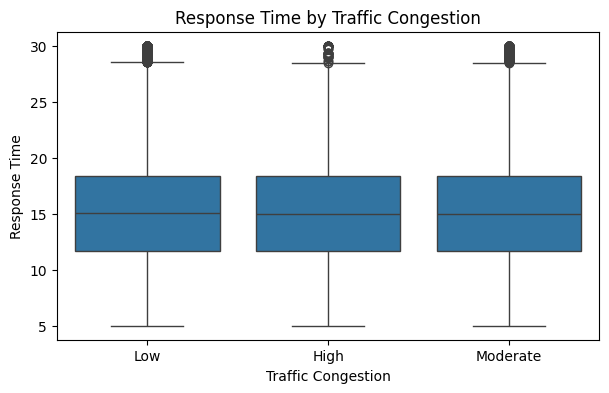

In [53]:
# 2- box plots 
#boxplot Response Time by Traffic Congestion

plt.figure(figsize=(7,4))
sns.boxplot(x='Traffic_Congestion', y='Response_Time', data=df_subset)

plt.title('Response Time by Traffic Congestion')
plt.xlabel('Traffic Congestion')
plt.ylabel('Response Time')
plt.show()
#Boxplots were used to compare the distribution of response time across different categories.
#They help us understand if response time values are close together or spread out.
#They also help identify possible outliers, which are incidents that took much longer than usual.

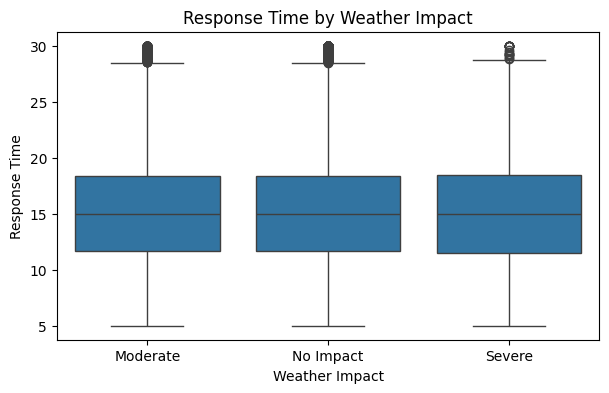

In [54]:
# boxplot Response Time by Weather Impact

plt.figure(figsize=(7,4))
sns.boxplot(x='Weather_Impact', y='Response_Time', data=df_subset)

plt.title('Response Time by Weather Impact')
plt.xlabel('Weather Impact')
plt.ylabel('Response Time')
plt.show()

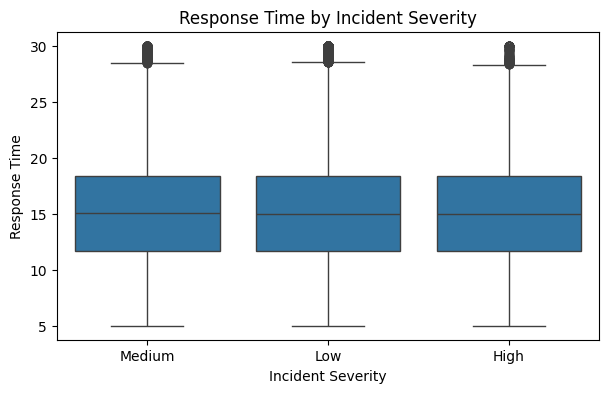

In [55]:
#boxplot Response Time by Incident Severity

plt.figure(figsize=(7,4))
sns.boxplot(x='Incident_Severity', y='Response_Time', data=df_subset)

plt.title('Response Time by Incident Severity')
plt.xlabel('Incident Severity')
plt.ylabel('Response Time')
plt.show()

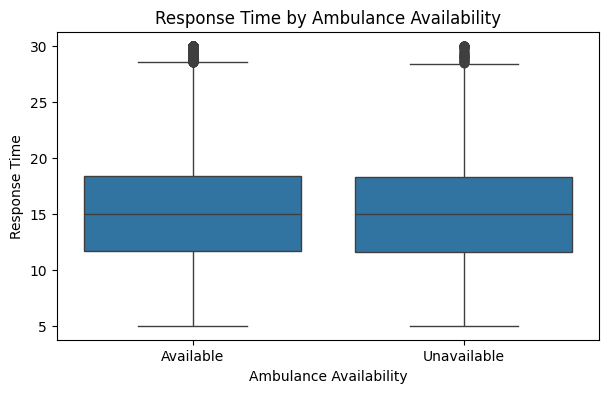

In [56]:
# boxplot Response Time by Ambulance Availability

plt.figure(figsize=(7,4))
sns.boxplot(x='Ambulance_Availability', y='Response_Time', data=df_subset)

plt.title('Response Time by Ambulance Availability')
plt.xlabel('Ambulance Availability')
plt.ylabel('Response Time')
plt.show()
# the data is so unclear 

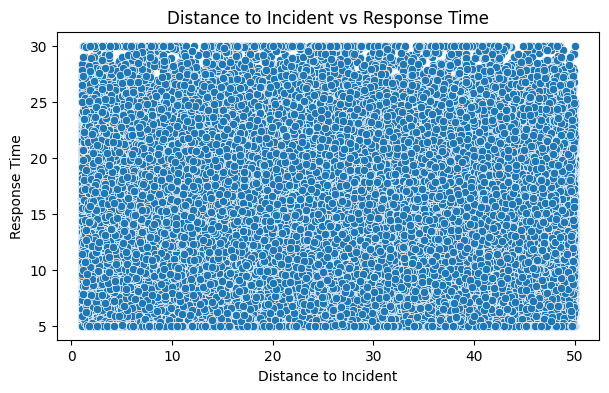

In [61]:
#3- scatter plot , see the realtion between the nunerical data 
# and response time 
# Scatter plot: Distance to Incident vs Response Time

plt.figure(figsize=(7,4))
sns.scatterplot(x='Distance_to_Incident', y='Response_Time', data=df_subset)

plt.title('Distance to Incident vs Response Time')
plt.xlabel('Distance to Incident')
plt.ylabel('Response Time')
plt.show()
#omg!, the realtions are so unclear 

In [62]:
# i`ll try to take a sample data to make it easier to read
sample_df = df_subset.sample(5000, random_state=42)

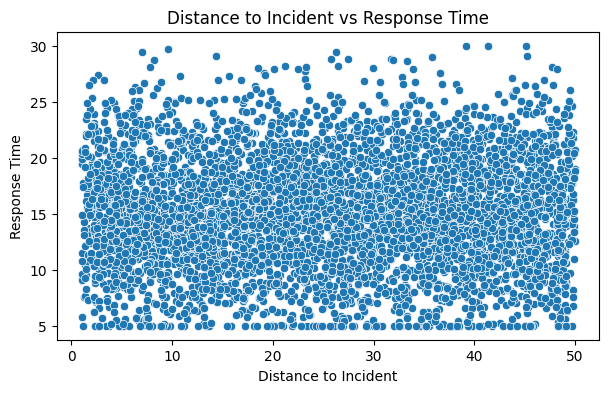

In [63]:
# Scatter plot: Distance to Incident vs Response Time

plt.figure(figsize=(7,4))
sns.scatterplot(x='Distance_to_Incident', y='Response_Time', data=sample_df)

plt.title('Distance to Incident vs Response Time')
plt.xlabel('Distance to Incident')
plt.ylabel('Response Time')
plt.show()
#still waek relatiobns, but better 

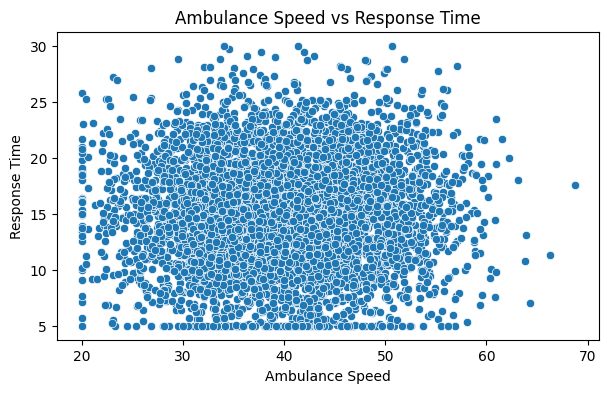

In [64]:
# Scatter plot: Ambulance Speed vs Response Time

plt.figure(figsize=(7,4))
sns.scatterplot(x='Ambulance_Speed', y='Response_Time', data=sample_df)

plt.title('Ambulance Speed vs Response Time')
plt.xlabel('Ambulance Speed')
plt.ylabel('Response Time')
plt.show()

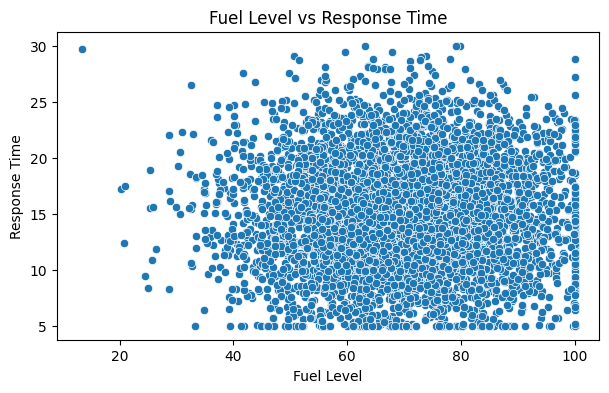

In [65]:
plt.figure(figsize=(7,4))
sns.scatterplot(x='Fuel_Level', y='Response_Time', data=sample_df)

plt.title('Fuel Level vs Response Time')
plt.xlabel('Fuel Level')
plt.ylabel('Response Time')
plt.show()

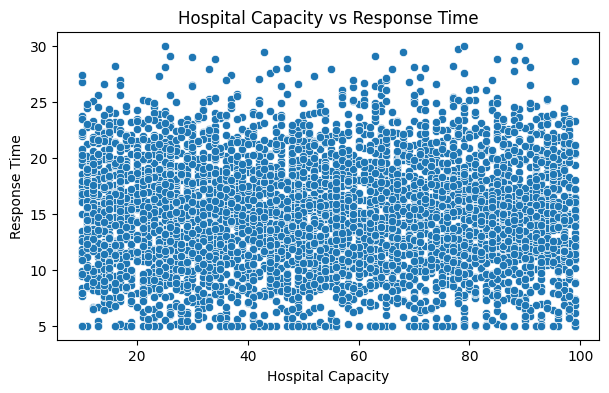

In [66]:
plt.figure(figsize=(7,4))
sns.scatterplot(x='Hospital_Capacity', y='Response_Time', data=sample_df)

plt.title('Hospital Capacity vs Response Time')
plt.xlabel('Hospital Capacity')
plt.ylabel('Response Time')
plt.show()
#Scatter plots were used to show the relationship between numerical variables and response time.
#They help us understand if variables such as
#distance, ambulance speed, fuel level, and hospital capacity are related to emergency response time.

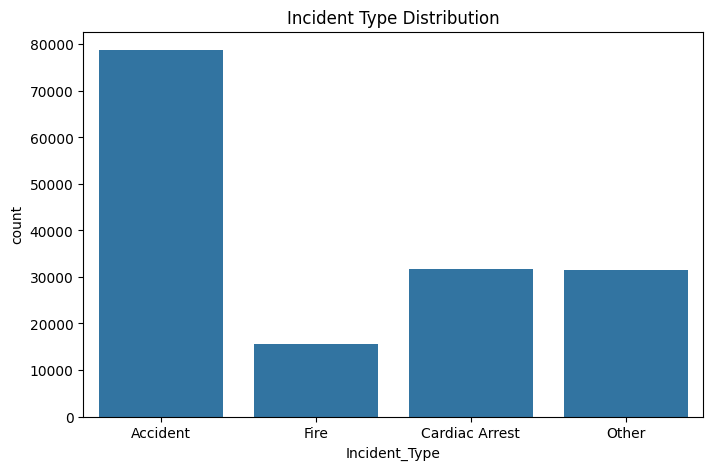

In [42]:
plt.figure(figsize=(8,5))
sns.countplot(
    x='Incident_Type',
    data=df_subset
)
plt.title("Incident Type Distribution")
plt.show()
#accident incidants appear most frequently in the dataset
#fire incidents haapens less often.
# Understanding incident frequency helps emergency centers to collect 
#resources more effectivly .

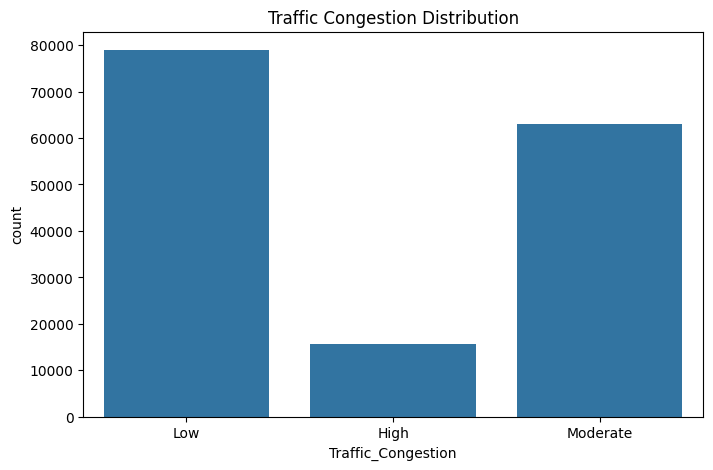

In [55]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Traffic_Congestion',
    data=df_subset
)

plt.title("Traffic Congestion Distribution")
plt.show()

# Insight:
# Low Traffic Congestion are the most common,
# while high Traffic Congestion occur less frequently.

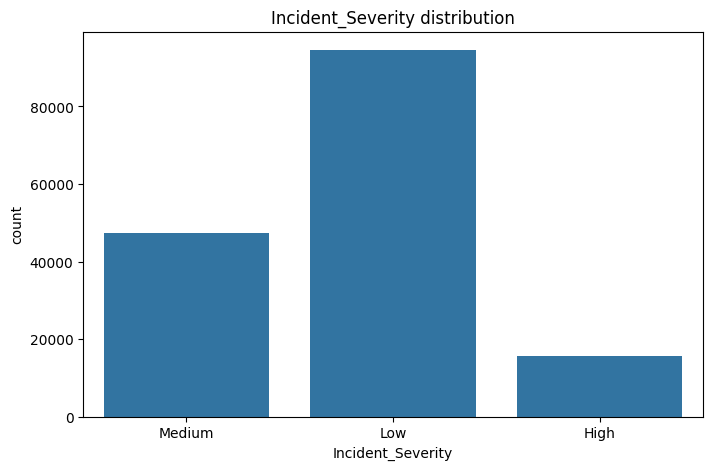

In [61]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Incident_Severity",
    data=df_subset
)
plt.title("Incident_Severity distribution")
plt.show()
# Insight:
# Low severity incidents are the most common,
# while high severity incidents occur less frequently.

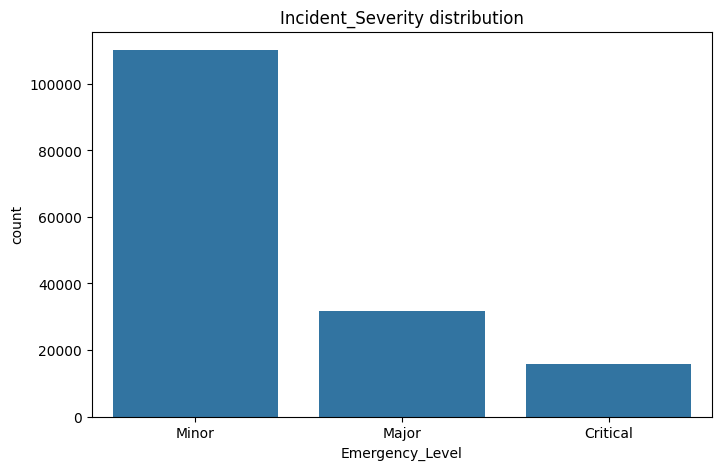

In [62]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Emergency_Level",
    data=df_subset
)
plt.title("Emergency Level distribution")
plt.show()
# Insight:
# Minor emergency cases are the most common,
# while critical cases occur less frequently.

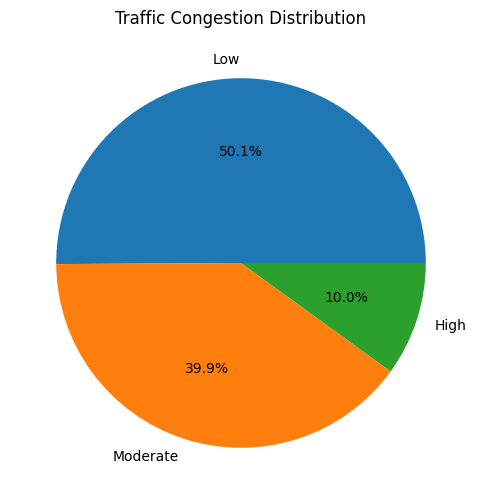

In [67]:
# id like to make a pie chat to identify the most common traffic congestion level.
traffic_counts = df_subset['Traffic_Congestion'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(traffic_counts,labels=traffic_counts.index,autopct='%1.1f%%')
plt.title('Traffic Congestion Distribution')
plt.show()

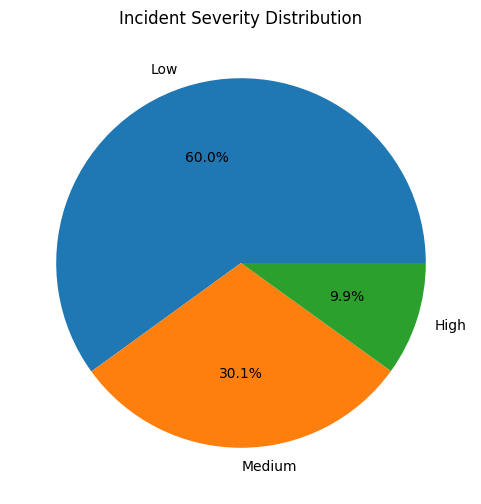

In [69]:
severity_counts = df_subset['Incident_Severity'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(severity_counts,labels=severity_counts.index,autopct='%1.1f%%')
plt.title('Incident Severity Distribution')
plt.show()

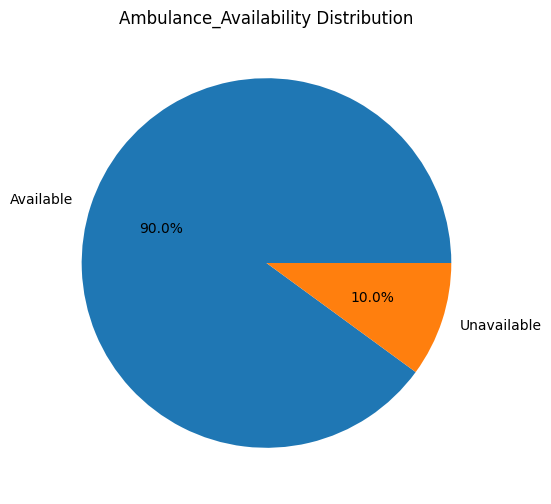

In [70]:
Ambulance_counts = df_subset['Ambulance_Availability'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(Ambulance_counts,labels=Ambulance_counts.index,autopct='%1.1f%%')
plt.title('Ambulance_Availability Distribution')
plt.show()

In [75]:
#after that, we want to analyse the resourdes availability 
#it was mentioned in the assignment 
#start with: 
#avg response time by specialist availability

specialist_response = df_subset.groupby('Specialist_Availability')['Response_Time'].mean()
specialist_response

Specialist_Availability
Available      15.083974
Unavailable    15.041069
Name: Response_Time, dtype: float64

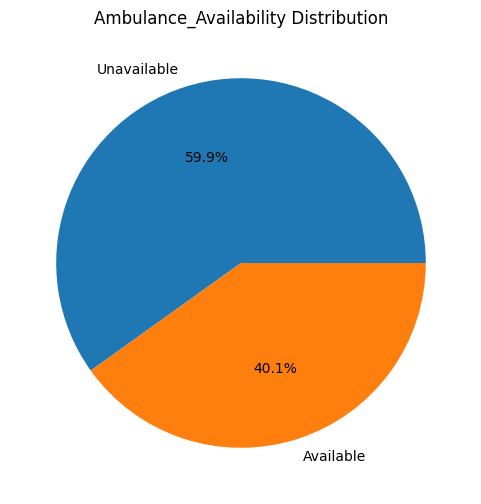

In [76]:


Specialist_counts = df_subset['Specialist_Availability'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(Specialist_counts,labels=Specialist_counts.index,autopct='%1.1f%%')
plt.title('Specialist_Availability Distribution')
plt.show()

In [71]:
#after that, we want to do time trent analyis
#is response time changes with time?
# we`re gonna calculate monthly avarage response time 
# Create a new column for month
df_subset['Month'] = df_subset['Timestamp'].dt.to_period('M')

# Calculate average response time for each month
monthly_response = df_subset.groupby('Month')['Response_Time'].mean()

monthly_response

C:\Users\HP\AppData\Local\Temp\ipykernel_18220\3261069281.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['Month'] = df_subset['Timestamp'].dt.to_period('M')


Month
2022-01    15.056992
2022-02    15.051928
2022-03    15.027851
2022-04    15.026545
2022-05    15.099888
2022-06    15.043578
2022-07    14.930030
2022-08    14.947270
2022-09    15.017795
2022-10    15.089000
2022-11    15.237586
2022-12    15.122509
2023-01    15.144675
2023-02    15.113008
2023-03    15.073439
2023-04    15.065814
2023-05    15.082602
2023-06    15.020497
2023-07    15.127484
2023-08    15.043150
2023-09    15.127785
2023-10    14.933119
2023-11    14.991376
2023-12    15.035772
2024-01    15.072797
2024-02    15.033079
2024-03    15.053511
2024-04    14.985794
2024-05    14.961007
2024-06    15.125622
2024-07    15.159929
2024-08    15.014094
2024-09    15.029799
2024-10    15.118404
2024-11    15.041195
2024-12    15.097855
Freq: M, Name: Response_Time, dtype: float64

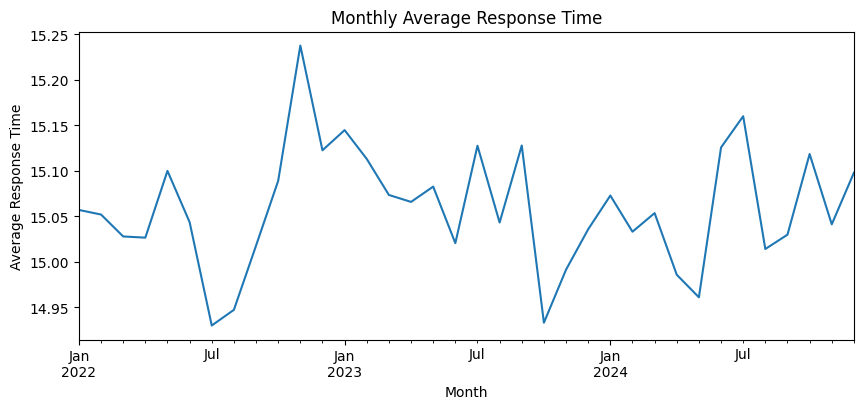

In [74]:
# Line chart for monthly average response time

plt.figure(figsize=(10,4))

monthly_response.plot(kind='line')

plt.title('Monthly Average Response Time')
plt.xlabel('Month')
plt.ylabel('Average Response Time')
plt.show()
#This line chart shows the monthly average response time.
#It helps us understand if emergency response performance changed over time.

In [78]:
#next : contingency table. 
# relatin between 2 catarogical coulmns 
#for example, i`ll choose to see the realtion between riegn type, and incident type 
region_incident_table = pd.crosstab(
    df_subset['Region_Type'],
    df_subset['Incident_Type']
)
region_incident_table

Incident_Type,Accident,Cardiac Arrest,Fire,Other
Region_Type,,,,
Rural,7783,3117,1598,3245
Suburban,15874,6393,3125,6351
Urban,55115,22246,10932,21902


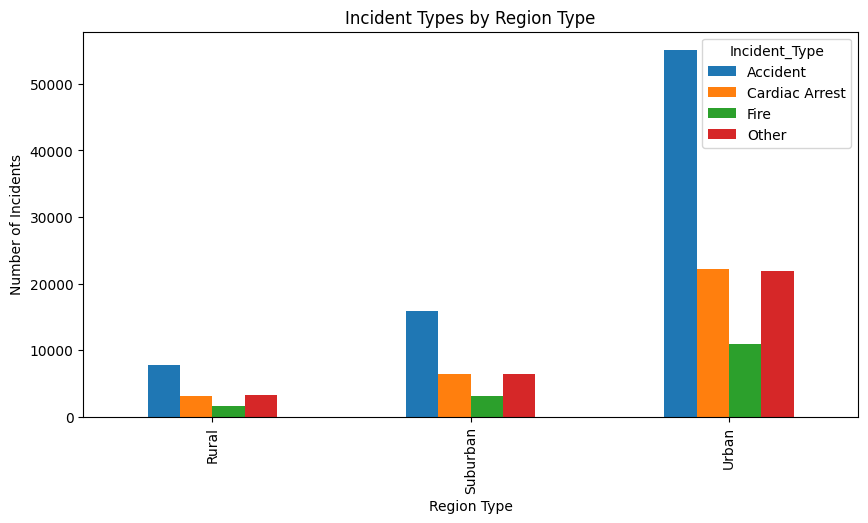

In [81]:
# Bar chart for incident types by region type
region_incident_table.plot(kind='bar', figsize=(10,5))
plt.title('Incident Types by Region Type')
plt.xlabel('Region Type')
plt.ylabel('Number of Incidents')
plt.show()
#This contingency table shows the relationship between region type and incident type.
#It helps us understand which incident types are more common in each region.

In [82]:
#because i finally sow some actual results, ill make another one
traffic_severity_table = pd.crosstab(
    df_subset['Traffic_Congestion'],
    df_subset['Incident_Severity'])
traffic_severity_table

Incident_Severity,High,Low,Medium
Traffic_Congestion,,,
High,1543,9491,4700
Low,7867,47279,23845
Moderate,6267,37812,18877


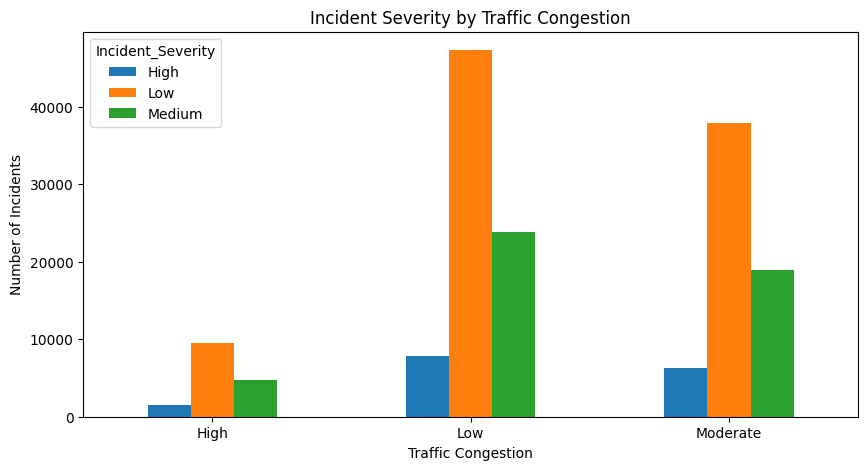

In [83]:
traffic_severity_table.plot(kind='bar', figsize=(10,5))
plt.title('Incident Severity by Traffic Congestion')
plt.xlabel('Traffic Congestion')
plt.ylabel('Number of Incidents')
plt.show()

In [84]:
weather_severity_table = pd.crosstab(
    df_subset['Weather_Impact'],
    df_subset['Incident_Severity'])
weather_severity_table

Incident_Severity,High,Low,Medium
Weather_Impact,,,
Moderate,3846,23654,12043
No Impact,11068,66278,32967
Severe,763,4650,2412


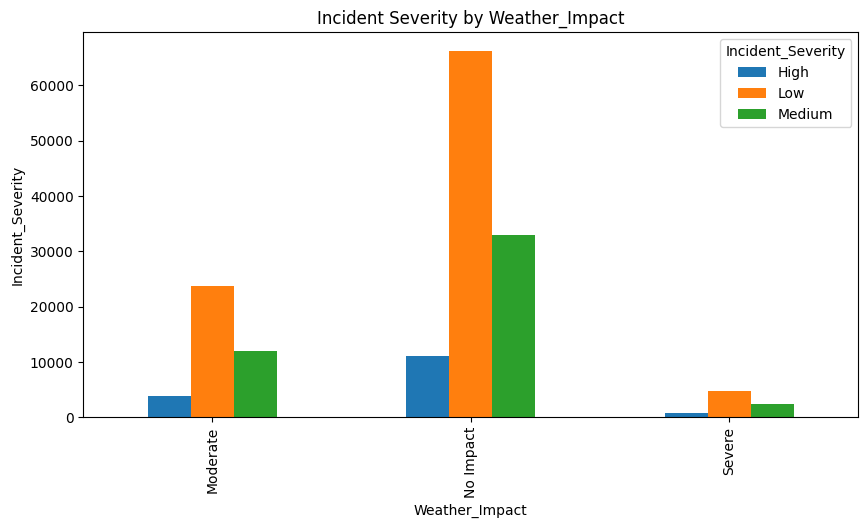

In [89]:
weather_severity_table.plot(kind='bar', figsize=(10,5))
plt.title('Incident Severity by Weather_Impact')
plt.xlabel('Weather_Impact')
plt.ylabel('Incident_Severity')
plt.show()

In [87]:
region_traffic_table = pd.crosstab(
    df_subset['Region_Type'],
    df_subset['Traffic_Congestion'])
region_traffic_table

Traffic_Congestion,High,Low,Moderate
Region_Type,,,
Rural,1608,7790,6345
Suburban,3103,15911,12729
Urban,11023,55290,43882


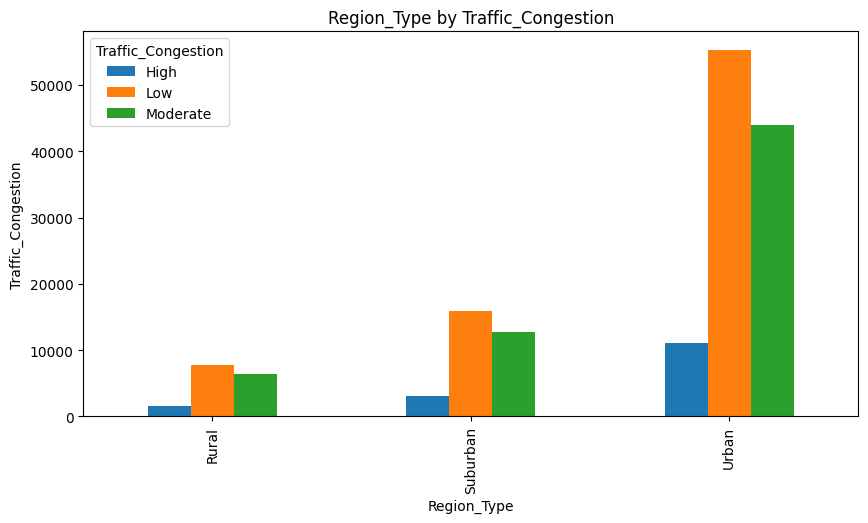

In [88]:
region_traffic_table.plot(kind='bar', figsize=(10,5))
plt.title('Region_Type by Traffic_Congestion')
plt.xlabel('Region_Type')
plt.ylabel('Traffic_Congestion')
plt.show()

In [57]:
df_subset[
    [
        'Response_Time',
        'Distance_to_Incident',
        'Fuel_Level',
        'Hospital_Capacity',
        'Ambulance_Speed'
    ]
].describe()

,Response_Time,Distance_to_Incident,Fuel_Level,Hospital_Capacity,Ambulance_Speed
count,157681.000000,157681.000000,157681.000000,157681.000000,157681.000000
mean,15.058278,25.506964,69.857698,54.523735,40.029138
std,4.891345,14.157189,14.677312,25.934344,7.959104
min,5.000000,1.000000,10.138465,10.000000,20.000000
25%,11.651596,13.240000,59.840729,32.000000,34.596855
50%,15.010456,25.510000,69.972216,54.000000,40.014632
75%,18.394115,37.790000,80.045142,77.000000,45.432415
max,30.000000,50.000000,100.000000,99.000000,77.801028


In [22]:
df_subset['Timestamp'].dt.year.unique()

array([2022, 2023, 2024], dtype=int32)

## final insigts :
Accident incidents were the most common type, urban areas had the highest number of incidents, and most cases had low severity. The data also showed that clear weather, low traffic congestion, and available ambulances were the most frequent conditions.

However, the average response time was very similar across traffic congestion levels, weather impact, incident severity, ambulance availability, and specialist availability. This means that these variables did not show a strong or clear relationship with response time in this dataset.

## conclusion : 

In this activity, descriptive analytics was used to understand the historical emergency response dataset. The analysis focused on response time and the main variables related to it, such as traffic congestion, weather impact, incident severity, region type, ambulance availability, and specialist availability.

Different descriptive techniques were applied, including summary statistics, central tendency, dispersion measures, frequency tables, groupby analysis, visualizations, scatter plots, line charts, pie charts, boxplots, and contingency tables.

The findings showed that some variables had weak relationships with response time, which may indicate weakly correlated data. However, descriptive analytics still helped identify patterns, understand emergency response performance, and support better planning, resource allocation, and data-driven decisions.